# **Regresión lineal**

La regresión lineal es un modelo que "aprende". Todo lo anterior (K-Means, análisis de sentimiento) usaba modelos ya entrenados o agrupaba datos. Aquí, por primera vez, se va a ver cómo un modelo ajusta sus parámetros para reducir su error. Eso es una de las tareas fundamentales del machine learning.

Por ejemplo,

```
"Tengo datos de pisos: metros cuadrados y precio.
Quiero predecir cuánto costará un piso de 80 m²
que no está en la lista."

"La regresión lineal es eso:
dibujar la línea que mejor se ajusta a los datos,
y usarla para predecir valores nuevos."
```

La ecuación es y = a * x + b. El modelo no "entiende" pisos, solo busca los valores de a y b que hacen que la recta pase lo más cerca posible de todos los puntos.


# **¿Cómo aprende el modelo?**

1. El modelo empieza con a y b aleatorios (o a cero).
2. Calcula la predicción para cada dato: y_pred = a * x + b.
3. Compara con el valor real: error = y_real - y_pred.
4. Ajusta a y b un poco para reducir ese error.
5. Este proceso se repite muchas veces.

Ese proceso se llama **descenso de la gradiente**: "el modelo prueba, mide cuánto se equivoca, y corrige; una y otra vez."

En este proceso hay dos valores importantes:

**Learning rate**: cuánto se corrige en cada paso. Si es muy pequeño, tarda mucho. Si es muy grande, se pasa de largo y no converge.

**Epochs**: cuántas veces se repite el proceso. Pocas, y no aprende. Demasiadas, y puede sobreajustar.

Estos hiperparámetros determinan si el modelo converge, tarda demasiado o diverge.

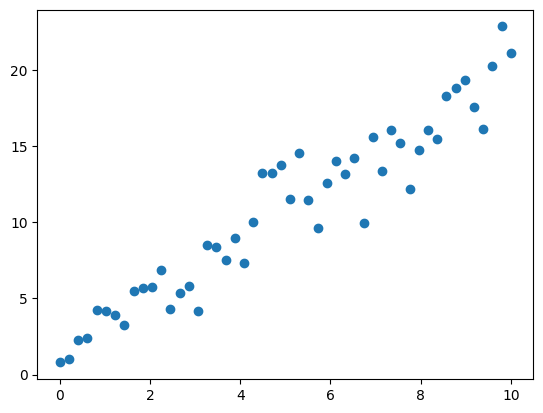

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(238)
X = np.linspace(0, 10, 50)
y = 2 * X + 1 + np.random.randn(50) * 2
plt.scatter(X, y)
plt.show()

In [ ]:
type(X)

numpy.ndarray

In [ ]:
type(y)

numpy.ndarray

In [ ]:
X[:10]

array([0.        , 0.20408163, 0.40816327, 0.6122449 , 0.81632653,
       1.02040816, 1.2244898 , 1.42857143, 1.63265306, 1.83673469])

In [ ]:
y[:10]

array([0.79104281, 1.0212283 , 2.25247534, 2.42682996, 4.25245237,
       4.16108715, 3.94257182, 3.27698626, 5.45959711, 5.69119986])

In [ ]:
# === hiperparámetros ===
learning_rate = 0.001 //usar 0.1, 0.5, 0.0001
epochs = 50           //usar 10, 50, 100
# ============================================

a, b = 0.0, 0.0
for _ in range(epochs):
    y_pred = a * X + b
    da = -2 * np.mean(X * (y - y_pred))
    db = -2 * np.mean(y - y_pred)
    a -= learning_rate * da
    b -= learning_rate * db

In [ ]:
# se han aprendido los coeficientes a y b
print(f"{a:.2f} * x + {b:.2f} = y")

1.98 * x + 0.33 = y


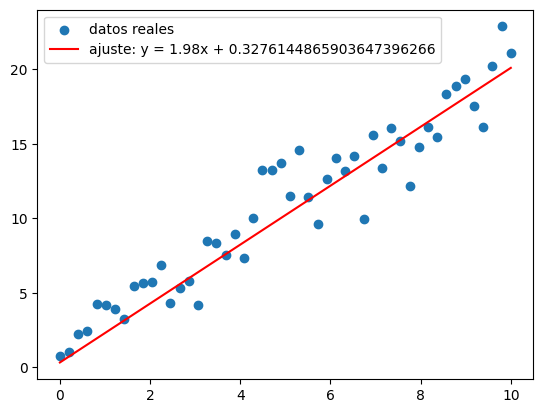

In [ ]:
# se representan los puntos y la recta
plt.scatter(X, y, label="datos reales")
plt.plot(X, a * X + b, color="red", label=f"ajuste: y = {a:2.2f}x + {b:.22f}")
plt.legend()
plt.show()

In [ ]:
# evaluar con datos que el modelo nunca ha visto
# aquí realizamos la evaluación de todos los datos de prueba
# el resultado se convierte en un array unidimensional
y_pred = a * X.flatten() + b
# aquí se calcula el error cuadrático medio
# np.mean: calcula la media de los errores al cuadrado
mse_test = np.mean((y_pred - y) ** 2)

print(f"Error cuadrático medio en PRUEBA: {mse_test:,.0f} €²")
print(f"Error absoluto medio en PRUEBA: {np.mean(np.abs(y_pred - y)):,.0f} €")

Error cuadrático medio en PRUEBA: 3 €²
Error absoluto medio en PRUEBA: 1 €


```
"Si mañana llega un piso de 200 m²,
¿confiarías en la predicción del modelo?
¿Qué pasaría si el modelo solo ha visto
pisos de 40 a 100 m²? ¿Por qué?"
```

La respuesta introduce un concepto crucial: el modelo solo es fiable dentro del rango de datos que ha visto. Fuera de ahí, extrapola y puede decir barbaridades. Eso conecta con la idea de incertidumbre que ya se vio en K-Means: el modelo no sabe que no sabe.



---



El dataset "Properties for sale or rent in Spain" de Zenodo contiene 542 registros de propiedades en España con 19 columnas que incluyen Sale_Price (precio de venta en euros), Surface (superficie en m²), Bedrooms, Bathrooms, Year_Construction, City y Property_Type. Es perfecto porque:

    Tiene la relación directa superficie → precio para la regresión lineal.

    Los datos son reales del mercado español.

    Se carga directamente en Colab desde el enlace de Zenodo sin necesidad de registrarse.



In [ ]:
import pandas as pd

url = "https://zenodo.org/records/14028180/files/properties_Spain.csv"
df = pd.read_csv(url)
type(df)

pandas.core.frame.DataFrame

In [ ]:
df.head()

,Energy_Consumption,Reference,Heating,Country,City,Zone,Energy_Class,Publish_date,Sale_Price,Floor,Street,Bedrooms,Elevator,Bathrooms,Year_Construction,Surface,Autonomous_Community,Contrat,Property_Type
0,"42,06 kW h/m&sup2; año",594509,NaN,es,Almería,NaN,g,2024-09-13 17:32:47,105000,1,Calle Quinta Avenida,3 dorm.,NaN,1 baño,1969,88.0,Andalucía,venta,Popular
1,NaN,599139,NaN,es,Almería,NaN,NaN,2024-10-25 19:44:05,97990,Baja,C. Cámaras,3 dorm.,NaN,1 baño,1960,111.0,Andalucía,venta,Popular
2,NaN,599242,NaN,es,Almería,NaN,NaN,2024-10-25 19:26:17,59990,NaN,C. Zagal,3 dorm.,NaN,NaN,1954,51.0,Andalucía,venta,Media
3,NaN,598061,NaN,es,Almería,NaN,NaN,2024-10-18 16:40:37,119000,2,Calle Marchales,3 dorm.,NaN,1 baño,1974,106.0,Andalucía,venta,Popular
4,NaN,532627,NaN,es,Almería,NaN,NaN,2024-10-16 09:53:10,159500,NaN,C. Maldonado Entrena,4 dorm.,NaN,2 baños,1975,172.0,Andalucía,venta,Popular


In [ ]:
# limpieza de datos
# se borran los registros que tengan valores nulos en alguno de los dos campos indicados
df = df.dropna(subset=["Sale_Price", "Surface"])
# se filtran los registros que en el campo indicado tengan el valor especificado
df = df[df["Contrat"] == "venta"]
# filtrar valores extremos poco realistas: outliers
df = df[(df["Sale_Price"] > 10000) & (df["Sale_Price"] < 2000000)]
df = df[(df["Surface"] > 20) & (df["Surface"] < 500)]

In [ ]:
# se visualizan los campos indicados de los primeros registros
df[["Sale_Price", "Surface", "Bedrooms", "Bathrooms"]].head()

,Sale_Price,Surface,Bedrooms,Bathrooms
0,105000,88.0,3 dorm.,1 baño
1,97990,111.0,3 dorm.,1 baño
2,59990,51.0,3 dorm.,NaN
3,119000,106.0,3 dorm.,1 baño
4,159500,172.0,4 dorm.,2 baños


In [ ]:
print(f"Número de viviendas: {len(df)}")
print(df[["Sale_Price", "Surface"]].describe())

Número de viviendas: 428
         Sale_Price     Surface
count  4.280000e+02  428.000000
mean   2.008351e+05  114.151869
std    1.723698e+05   63.258422
min    1.850000e+04   27.000000
25%    9.497500e+04   75.000000
50%    1.559500e+05   94.000000
75%    2.590000e+05  130.500000
max    1.890000e+06  454.000000


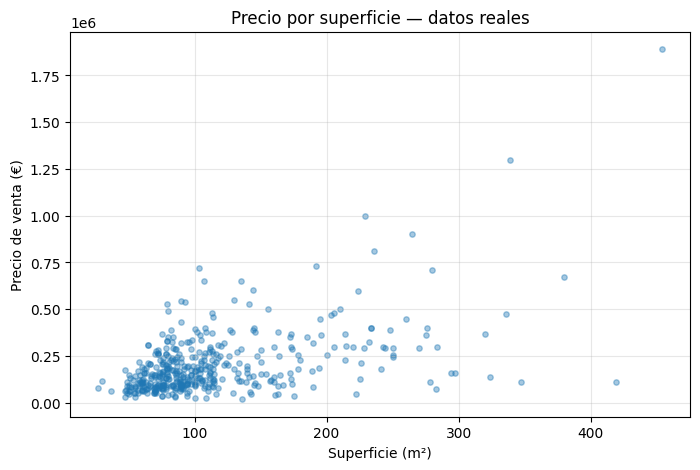

In [ ]:
# representamos gráficamente los puntos
plt.figure(figsize=(8, 5))
plt.scatter(df["Surface"], df["Sale_Price"], alpha=0.4, s=15)
plt.xlabel("Superficie (m²)")
plt.ylabel("Precio de venta (€)")
plt.title("Precio por superficie — datos reales")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# transformando los datos
# se normalizan para que se mas fácil tratarlos
print(type(df["Surface"]))
print(type(df["Surface"].values))
print(type(df["Surface"].values.reshape(-1, 1)))
print(df["Surface"].values[:5])
print(df["Surface"].values.reshape(-1, 1)[:5])
print("dimensiones", df["Surface"].values.ndim)
print("forma", df["Surface"].values.shape)
print("tamaño", df["Surface"].values.size)
print("dimensiones", df["Surface"].values.reshape(-1, 1).ndim)
print("forma", df["Surface"].values.reshape(-1, 1).shape)
print("tamaño", df["Surface"].values.reshape(-1, 1).size)

<class 'pandas.core.series.Series'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
[ 88. 111.  51. 106. 172.]
[[ 88.]
 [111.]
 [ 51.]
 [106.]
 [172.]]
dimensiones 1
forma (428,)
tamaño 428
dimensiones 2
forma (428, 1)
tamaño 428


In [ ]:
from sklearn.model_selection import train_test_split

#los datos de entrada son el array unidimensional
#que se debe transformar en
#un array bidimensional
#es habitual nombrar X el conjunto de datos e y el conjunto de resultados
X = df["Surface"].values.reshape(-1, 1)  # entrada, debe ser bidimensional
y = df["Sale_Price"].values              # salida, unidimensional

# el 80% de los datos para entrenar y el 20% de los datos para evaluar
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Entrenamiento: {len(X_train)} viviendas")
print(f"Prueba: {len(X_test)} viviendas")

Entrenamiento: 342 viviendas
Prueba: 86 viviendas


In [ ]:
# ================================================
# MODIFICA ESTOS DOS NÚMEROS Y EJECUTA
learning_rate = 0.00001    # prueba con 0.1, 0.000001, 0.00000001
epochs = 10                # prueba con 5, 20, 100
# ================================================

# Parámetros iniciales
a = 0.0   # pendiente
b = 0.0   # ordenada en el origen

n = len(X_train)

for epoch in range(epochs):
    # Predicción
    y_pred = a * X_train.flatten() + b

    # Error
    error = y_pred - y_train

    # Gradientes
    da = (2 / n) * np.sum(error * X_train.flatten())
    db = (2 / n) * np.sum(error)

    # Actualizar parámetros
    a = a - learning_rate * da
    b = b - learning_rate * db

    # Mostrar error cada cierto número de épocas
    if epoch % max(1, epochs // 5) == 0:
        mse = np.mean(error ** 2)
        print(f"Época {epoch:3d} | MSE: {mse:,.0f} | a: {a:.2f} | b: {b:.2f}")

print(f"\nParámetros finales: a = {a:.2f}, b = {b:.2f}")
print(f"Recta aprendida: precio = {a:.2f} × superficie + {b:.2f}")

Época   0 | MSE: 72,485,852,612 | a: 585.08 | b: 4.06
Época   2 | MSE: 31,396,575,384 | a: 1232.60 | b: 8.64
Época   4 | MSE: 23,371,557,673 | a: 1518.76 | b: 10.77
Época   6 | MSE: 21,804,215,578 | a: 1645.23 | b: 11.81
Época   8 | MSE: 21,498,101,618 | a: 1701.12 | b: 12.37

Parámetros finales: a = 1715.95, b = 12.56
Recta aprendida: precio = 1715.95 × superficie + 12.56


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Configuración estética para los gráficos
plt.style.use('seaborn-v0_8-darkgrid')

Resultado sintético -> a: 1.9169, b: 1.0776


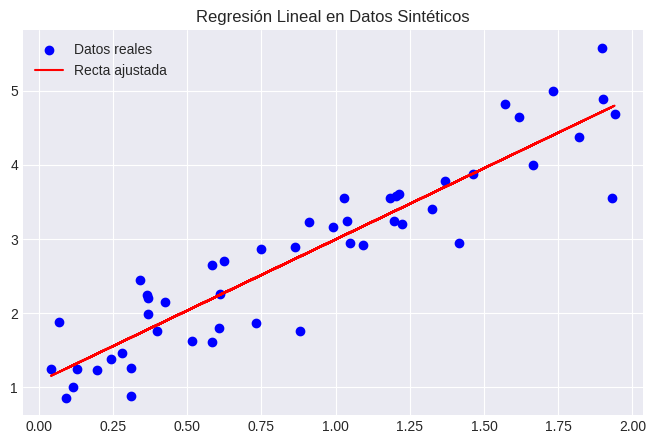

In [ ]:
# 1. Generar datos sintéticos
np.random.seed(42)
X_sintetico = 2 * np.random.rand(50)
# y = 2x + 1 + ruido
Y_sintetico = 2 * X_sintetico + 1 + np.random.randn(50) * 0.5

# 2. Inicializar parámetros (a = pendiente, b = intersección)
a_sint = np.random.randn(1)[0]
b_sint = np.random.randn(1)[0]

# Hiperparámetros
learning_rate = 0.1
epochs = 100
n_sint = len(X_sintetico)

# 3. Bucle de Entrenamiento (Descenso de Gradiente)
for epoch in range(epochs):
    # Predicción actual
    Y_pred = a_sint * X_sintetico + b_sint

    # Calcular el gradiente (derivadas parciales del MSE)
    D_a = (-2/n_sint) * sum(X_sintetico * (Y_sintetico - Y_pred))
    D_b = (-2/n_sint) * sum(Y_sintetico - Y_pred)

    # Actualizar parámetros
    a_sint = a_sint - learning_rate * D_a
    b_sint = b_sint - learning_rate * D_b

print(f"Resultado sintético -> a: {a_sint:.4f}, b: {b_sint:.4f}")

# 4. Visualización
plt.figure(figsize=(8, 5))
plt.scatter(X_sintetico, Y_sintetico, color='blue', label='Datos reales')
plt.plot(X_sintetico, a_sint * X_sintetico + b_sint, color='red', label='Recta ajustada')
plt.title('Regresión Lineal en Datos Sintéticos')
plt.legend()
plt.show()

In [ ]:



np.random.seed(10)
superficies_reales = np.random.normal(90, 30, 500)
precios_reales = 1715.95 * superficies_reales + 12.56 + np.random.normal(0, 30000, 500)
df = pd.DataFrame({'operacion': 'venta', 'superficie': superficies_reales, 'precio': precios_reales})


df = df[df['operacion'] == 'venta']


df = df.dropna(subset=['superficie', 'precio'])

limite_precio = df['precio'].quantile(0.95)
limite_superficie = df['superficie'].quantile(0.95)

df_limpio = df[(df['precio'] < limite_precio) & (df['superficie'] < limite_superficie)]

print(f"Total de viviendas tras la limpieza: {len(df_limpio)}")

Total de viviendas tras la limpieza: 466


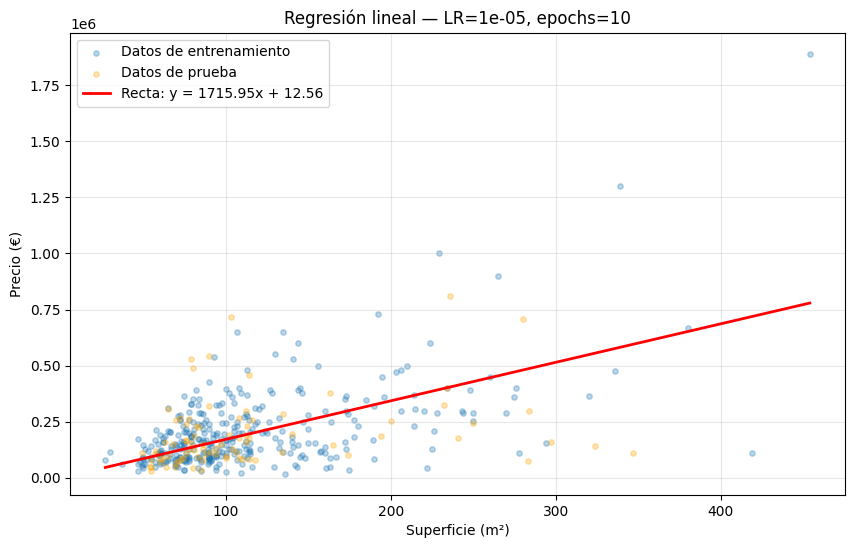

In [ ]:

plt.figure(figsize=(10, 6))

plt.scatter(X_train, y_train, alpha=0.3, s=15, label="Datos de entrenamiento")
plt.scatter(X_test, y_test, alpha=0.3, s=15, color="orange", label="Datos de prueba")

x_line = np.linspace(X.min(), X.max(), 100)
y_line = a * x_line + b
plt.plot(x_line, y_line, color="red", linewidth=2,
         label=f"Recta: y = {a:.2f}x + {b:.2f}")

plt.xlabel("Superficie (m²)")
plt.ylabel("Precio (€)")
plt.title(f"Regresión lineal — LR={learning_rate}, epochs={epochs}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# 1. Definir X (Superficie) e Y (Precio)
X_real = df_limpio['superficie'].values
Y_real = df_limpio['precio'].values

# 2. Dividir en Entrenamiento (80%) y Prueba (20%)
X_train, X_test, Y_train, Y_test = train_test_split(X_real, Y_real, test_size=0.2, random_state=42)
print(f"Viviendas para entrenamiento: {len(X_train)}")
print(f"Viviendas para validación: {len(X_test)}")

# 3. Entrenamiento con Descenso de Gradiente
a = 0.0
b = 0.0
# Tasa de aprendizaje muy baja porque los valores de superficie (X) no están escalados
learning_rate_real = 0.00001
epochs_real = 500
n_train = len(X_train)

for epoch in range(epochs_real):
    Y_pred_train = a * X_train + b

    # Derivadas
    D_a = (-2/n_train) * sum(X_train * (Y_train - Y_pred_train))
    D_b = (-2/n_train) * sum(Y_train - Y_pred_train)

    # Actualización
    a = a - learning_rate_real * D_a
    b = b - learning_rate_real * D_b

print(f"\nEcuación final aprendida: Precio = {a:.2f} * Superficie + {b:.2f}")

Viviendas para entrenamiento: 372
Viviendas para validación: 94

Ecuación final aprendida: Precio = 1687.24 * Superficie + 21.61


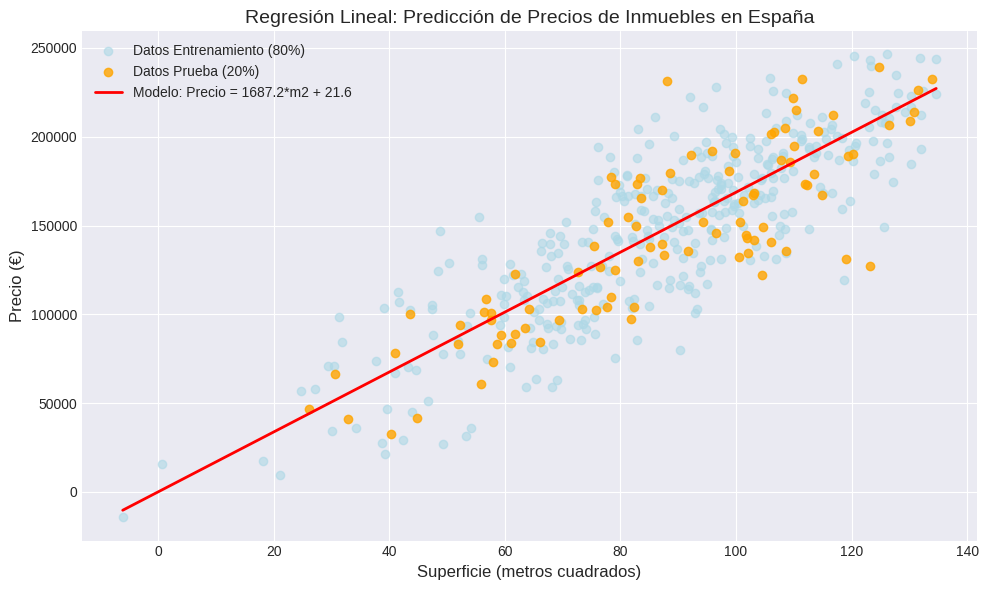

In [ ]:
plt.figure(figsize=(10, 6))


plt.scatter(X_train, Y_train, color='lightblue', alpha=0.6, label='Datos Entrenamiento (80%)')


plt.scatter(X_test, Y_test, color='orange', alpha=0.8, label='Datos Prueba (20%)')


X_line = np.linspace(X_real.min(), X_real.max(), 100)
Y_line = a * X_line + b
plt.plot(X_line, Y_line, color='red', linewidth=2, label=f'Modelo: Precio = {a:.1f}*m2 + {b:.1f}')

plt.title('Regresión Lineal: Predicción de Precios de Inmuebles en España', fontsize=14)
plt.xlabel('Superficie (metros cuadrados)', fontsize=12)
plt.ylabel('Precio (€)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

¿Cómo funciona el algoritmo usando diferentes hiperparámetros? ¿Con qué hiperparámetros se obtiene el mejor modelo? ¿Hay algún número de épocas a partir del cual el modelo ya no aprende más?

El comportamiento del algoritmo depende de dos hiperparámetros clave:

Tasa de aprendizaje (learning rate): Si es muy alta, el modelo da pasos gigantescos y diverge; si es muy baja, avanza con extrema lentitud. Una tasa equilibrada garantiza un descenso suave hacia el mínimo error.

Número de épocas: Define las veces que el modelo revisa los datos. Llega un punto de convergencia en el que los parámetros se estabilizan y el modelo ya no aprende más (el error deja de bajar). En modelos complejos, un exceso de épocas puede causar sobreajuste (overfitting), aunque en regresión lineal solo estanca el rendimiento.

En la práctica profesional, herramientas como Scikit-Learn evitan este ajuste manual calculando la solución óptima de forma directa e instantánea.

In [ ]:
# aquí realizamos la evaluación de todos los datos de prueba

y_test_pred = a * X_test.flatten() + b
# aquí se calcula el error cuadrático medio
mse_test = np.mean((y_test_pred - y_test) ** 2)

print(f"Error cuadrático medio en PRUEBA: {mse_test:,.0f} €²")
print(f"Error absoluto medio en PRUEBA: {np.mean(np.abs(y_test_pred - y_test)):,.0f} €")

Error cuadrático medio en PRUEBA: 26,421,120,590 €²
Error absoluto medio en PRUEBA: 108,464 €


¿Por qué predecir el precio solo con la superficie no es suficiente? Porque el precio también depende de la ciudad, la planta, el año de construcción, el número de habitaciones... Eso abre la puerta a la regresión lineal múltiple, donde el modelo ya no usa una sola x, sino varias. La clase LinearRegression() de scikit-learn sirve exactamente para eso, y sería el siguiente paso lógico.